# 03 — Stratified Train-Test Split & 5-Fold Development CV Setup

**Skrip CLI:** [`src/03_stratified_split.py`](../src/03_stratified_split.py)  
**Laporan:** [`Laporan_Stratified_Split_DIFW_KNN.md`](../Laporan_Stratified_Split_DIFW_KNN.md)

Tahap ini mengimplementasikan simpul **Stratified Train-Test Split** pada *flowchart* penelitian:
1. Memisahkan `45.211` observasi menjadi **Training / Development Data** (`80%` = `36.168` baris) dan **Hold-out Test Data** (`20%` = `9.043` baris) dengan `random_state=42`.
2. Membuktikan keseimbangan distribusi fitur (*Covariate Balance Check*) antara Train dan Hold-out Test menggunakan **Kolmogorov-Smirnov** (numerik) dan **Chi-Square** (kategorikal).
3. Mengunci indeks **Stratified 5-Fold Cross-Validation** (`train_cv_folds.csv`) agar `Baseline KNN` (`E0`–`E1`) dan `Proposed DIFW-KNN` (`E2`–`E5`) dievaluasi pada lipatan yang **100% identik**.

## 1. Pembagian Stratified Train-Test Split (80:20)

In [1]:
import importlib.util
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 120, 'axes.edgecolor': '#CCCCCC', 'axes.grid': True,
    'grid.alpha': 0.3, 'grid.linestyle': '--', 'axes.titleweight': 'bold',
})

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    DEFAULT_RANDOM_STATE, DEFAULT_TEST_SIZE,
    clean_deterministic, load_raw_dataset, stratified_split_data
)
spec = importlib.util.spec_from_file_location('split_mod', PROJECT_ROOT / 'src' / '03_stratified_split.py')
split_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(split_mod)

raw_df = load_raw_dataset(PROJECT_ROOT / 'bank-full.csv')
X_clean, y_clean = clean_deterministic(raw_df)
X_train, X_test, y_train, y_test = stratified_split_data(
    X_clean, y_clean, test_size=DEFAULT_TEST_SIZE, random_state=DEFAULT_RANDOM_STATE
)

split_tbl = pd.DataFrame([
    {'subset': 'Full (Cleaned)', 'n_rows': len(X_clean), 'n_no': int((y_clean == 0).sum()), 'n_yes': int(y_clean.sum()), 'pct_yes': round(100*float(y_clean.mean()), 4)},
    {'subset': 'Training / Dev (80%)', 'n_rows': len(X_train), 'n_no': int((y_train == 0).sum()), 'n_yes': int(y_train.sum()), 'pct_yes': round(100*float(y_train.mean()), 4)},
    {'subset': 'Hold-out Test (20%)', 'n_rows': len(X_test), 'n_no': int((y_test == 0).sum()), 'n_yes': int(y_test.sum()), 'pct_yes': round(100*float(y_test.mean()), 4)},
])
display(split_tbl)

,subset,n_rows,n_no,n_yes,pct_yes
0,Full (Cleaned),45211,39922,5289,11.6985
1,Training / Dev (80%),36168,31937,4231,11.6982
2,Hold-out Test (20%),9043,7985,1058,11.6997


## 2. Uji Keseimbangan Distribusi Kovariat (*Covariate Balance Check*: Train vs Hold-out Test)

In [2]:
num_balance = split_mod.check_numeric_covariate_balance(X_train, X_test)
cat_balance = split_mod.check_categorical_covariate_balance(X_train, X_test)
print(f"Fitur numerik seimbang (p >= 0.05)    : {int(num_balance['balanced_at_alpha_0_05'].sum())}/{len(num_balance)}")
print(f"Fitur kategorikal seimbang (p >= 0.05): {int(cat_balance['balanced_at_alpha_0_05'].sum())}/{len(cat_balance)}")
display(num_balance)
display(cat_balance)

Fitur numerik seimbang (p >= 0.05)    : 6/6
Fitur kategorikal seimbang (p >= 0.05): 9/9


,feature,train_mean,test_mean,train_median,test_median,ks_stat,p_value,balanced_at_alpha_0_05
0,age,40.8930,41.1090,39.0,39.0,0.01160,0.2824,True
1,balance,1365.4934,1349.3880,451.0,437.0,0.01110,0.3328,True
2,day,15.8180,15.7603,16.0,16.0,0.00734,0.8281,True
3,campaign,2.7639,2.7635,2.0,2.0,0.00251,1.0000,True
4,pdays,40.1572,40.3602,-1.0,-1.0,0.00499,0.9934,True
5,previous,0.5817,0.5747,0.0,0.0,0.00496,0.9938,True


,feature,n_categories,chi2_stat,dof,p_value,balanced_at_alpha_0_05
0,job,12,10.5001,11,0.4860,True
1,marital,3,0.0354,2,0.9825,True
2,education,4,3.3715,3,0.3378,True
3,default,2,0.1571,1,0.6918,True
4,housing,2,3.4017,1,0.0651,True
5,loan,2,0.3120,1,0.5764,True
6,contact,3,0.8549,2,0.6522,True
7,month,12,18.0328,11,0.0808,True
8,poutcome,4,2.0035,3,0.5717,True


## 3. Penyiapan Stratified 5-Fold Cross-Validation & Visualisasi Keseimbangan

,fold_id,n_train_fold,n_val_fold,n_train_yes,pct_train_yes,n_val_yes,pct_val_yes
0,0,28934,7234,3385,11.6990,846,11.6948
1,1,28934,7234,3385,11.6990,846,11.6948
2,2,28934,7234,3384,11.6956,847,11.7086
3,3,28935,7233,3385,11.6986,846,11.6964
4,4,28935,7233,3385,11.6986,846,11.6964


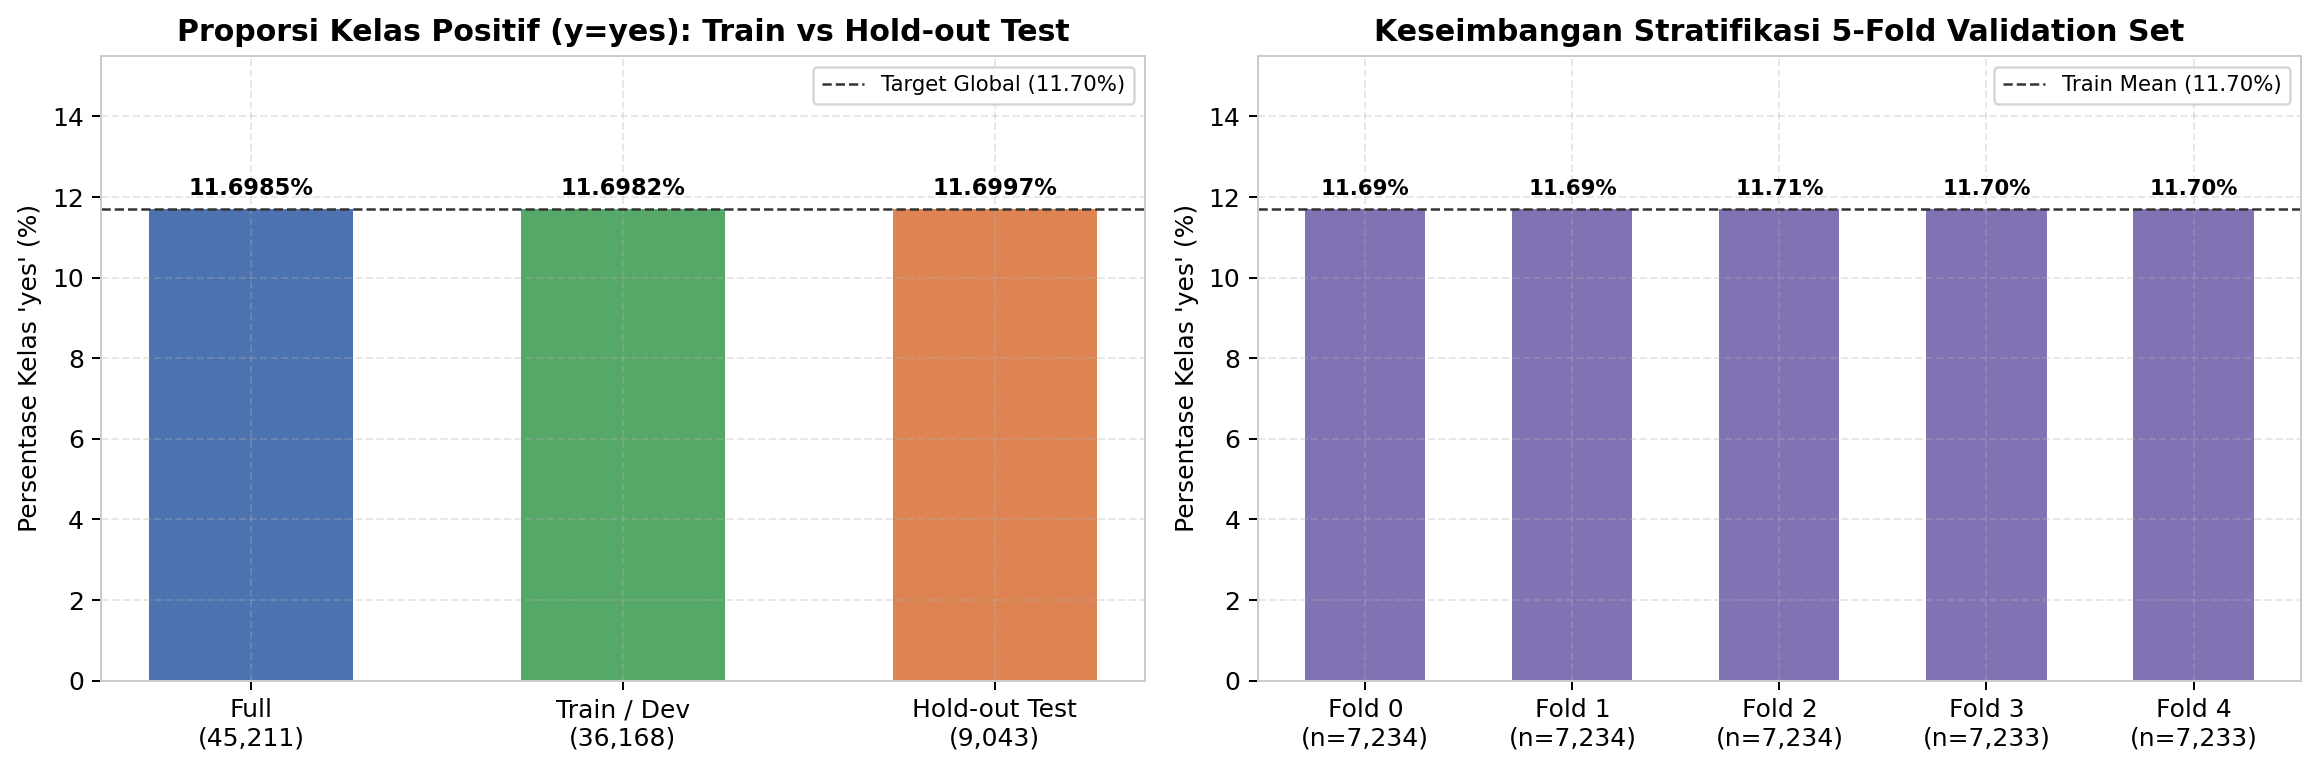

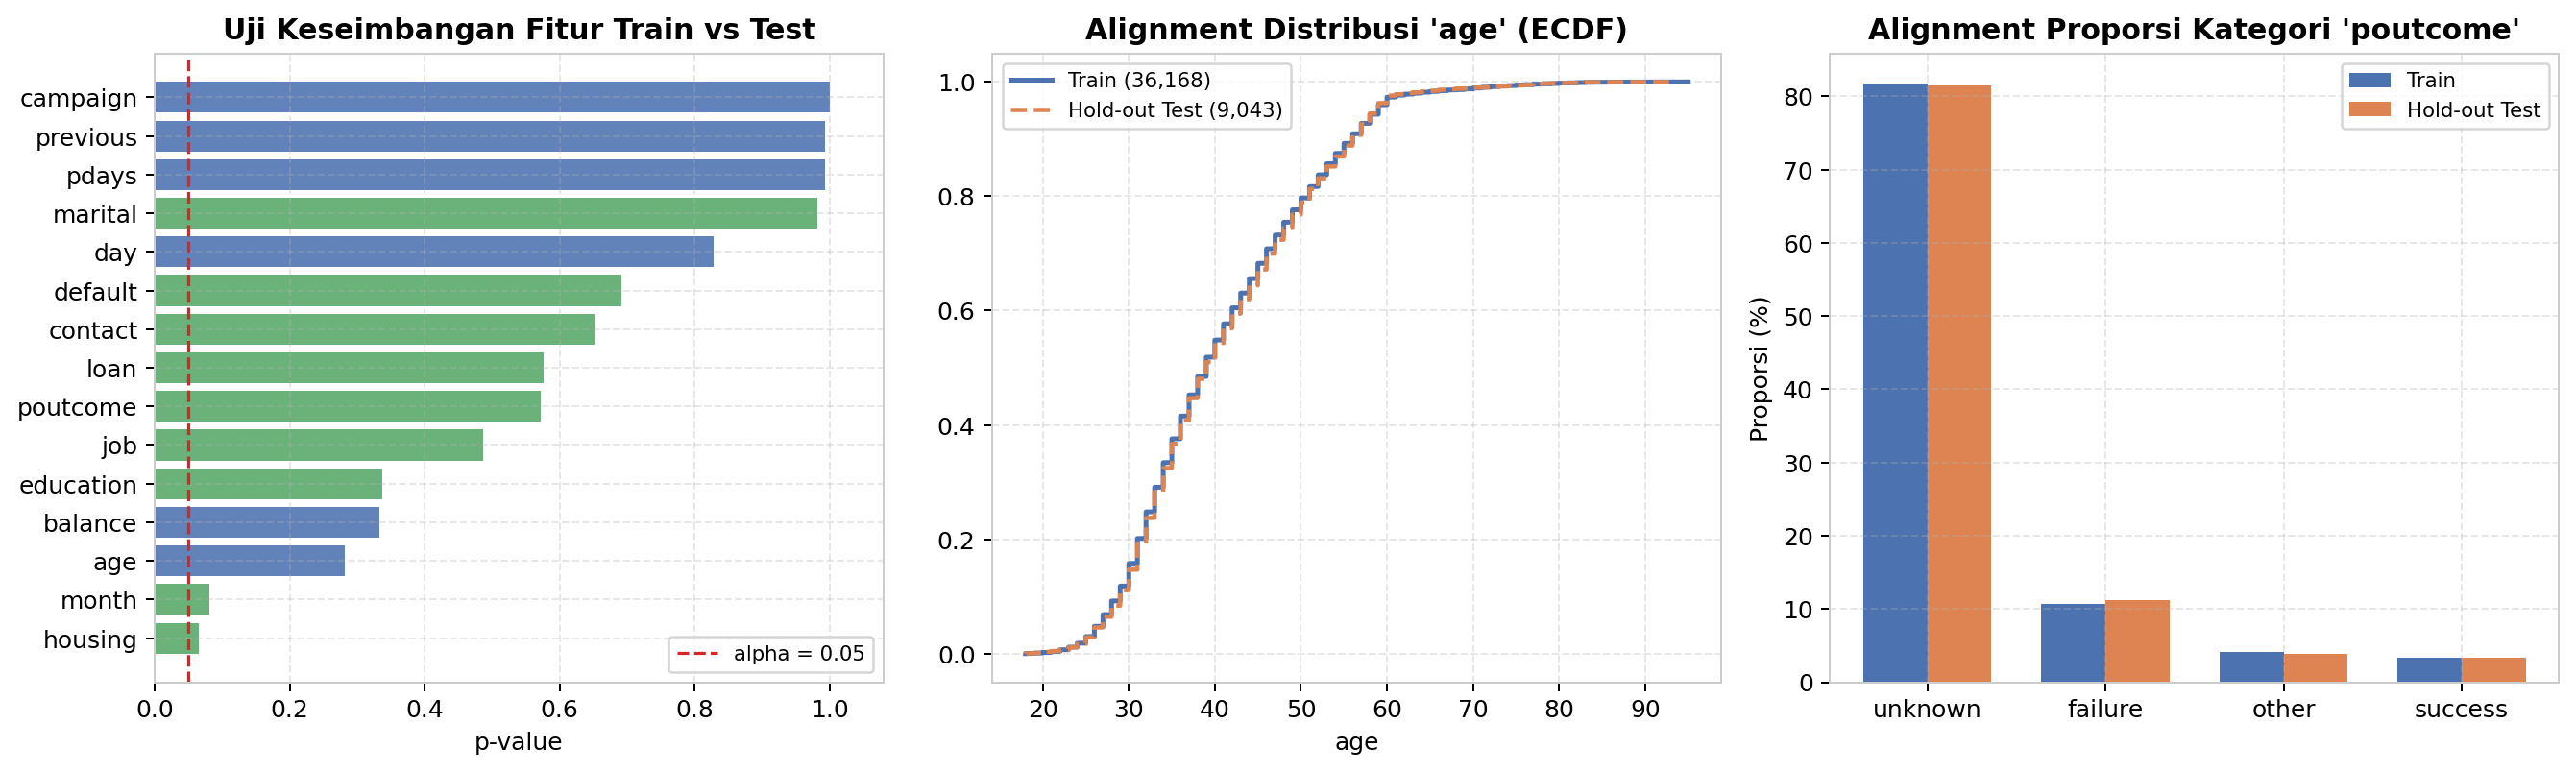

In [3]:
folds_df, cv_summary = split_mod.build_cv_folds(y_train, n_splits=5, random_state=DEFAULT_RANDOM_STATE)
display(cv_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
labels_s = [f'Full\n({len(y_clean):,})', f'Train / Dev\n({len(y_train):,})', f'Hold-out Test\n({len(y_test):,})']
pct_s = [100*float(y_clean.mean()), 100*float(y_train.mean()), 100*float(y_test.mean())]
bars_s = axes[0].bar(labels_s, pct_s, color=['#4C72B0', '#55A868', '#DD8452'], width=0.55)
axes[0].axhline(pct_s[0], color='#333333', linestyle='--', linewidth=1, label=f'Target Global ({pct_s[0]:.2f}%)')
axes[0].set_title('Proporsi Kelas Positif (y=yes): Train vs Hold-out Test')
axes[0].set_ylabel("Persentase Kelas 'yes' (%)")
axes[0].set_ylim(0, 15.5)
axes[0].legend(fontsize=8.5)
for bar, v in zip(bars_s, pct_s):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 0.35, f'{v:.4f}%', ha='center', fontweight='bold', fontsize=9)

fold_lbls = [f'Fold {int(f)}\n(n={int(n):,})' for f, n in zip(cv_summary['fold_id'], cv_summary['n_val_fold'])]
bars_f = axes[1].bar(fold_lbls, cv_summary['pct_val_yes'], color='#8172B3', width=0.58)
axes[1].axhline(pct_s[1], color='#333333', linestyle='--', linewidth=1, label=f'Train Mean ({pct_s[1]:.2f}%)')
axes[1].set_title('Keseimbangan Stratifikasi 5-Fold Validation Set')
axes[1].set_ylabel("Persentase Kelas 'yes' (%)")
axes[1].set_ylim(0, 15.5)
axes[1].legend(fontsize=8.5)
for bar, v in zip(bars_f, cv_summary['pct_val_yes']):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.35, f'{v:.2f}%', ha='center', fontweight='bold', fontsize=8.5)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
comb_p = pd.concat([num_balance[['feature', 'p_value']].assign(kind='KS'), cat_balance[['feature', 'p_value']].assign(kind='Chi2')], ignore_index=True).sort_values('p_value')
axes[0].barh(comb_p['feature'], comb_p['p_value'], color=['#4C72B0' if k == 'KS' else '#55A868' for k in comb_p['kind']], alpha=0.88)
axes[0].axvline(0.05, color='#D62728', linestyle='--', linewidth=1.3, label='alpha = 0.05')
axes[0].set_title('Uji Keseimbangan Fitur Train vs Test')
axes[0].set_xlabel('p-value')
axes[0].set_xlim(0, 1.08)
axes[0].legend(fontsize=8.5, loc='lower right')

tr_age = np.sort(X_train['age'].astype(float).to_numpy())
te_age = np.sort(X_test['age'].astype(float).to_numpy())
axes[1].plot(tr_age, np.linspace(0, 1, len(tr_age)), label='Train (36,168)', color='#4C72B0', linewidth=2)
axes[1].plot(te_age, np.linspace(0, 1, len(te_age)), label='Hold-out Test (9,043)', color='#DD8452', linestyle='--', linewidth=1.8)
axes[1].set_title("Alignment Distribusi 'age' (ECDF)")
axes[1].set_xlabel('age')
axes[1].legend(fontsize=8.5)

tr_p = 100.0 * X_train['poutcome'].value_counts(normalize=True)
te_p = 100.0 * X_test['poutcome'].value_counts(normalize=True)
cats = ['unknown', 'failure', 'other', 'success']
xc = np.arange(len(cats))
axes[2].bar(xc - 0.18, [tr_p.get(c, 0.0) for c in cats], width=0.36, label='Train', color='#4C72B0')
axes[2].bar(xc + 0.18, [te_p.get(c, 0.0) for c in cats], width=0.36, label='Hold-out Test', color='#DD8452')
axes[2].set_xticks(xc)
axes[2].set_xticklabels(cats)
axes[2].set_title("Alignment Proporsi Kategori 'poutcome'")
axes[2].set_ylabel('Proporsi (%)')
axes[2].legend(fontsize=8.5)
fig.tight_layout()
plt.show()